In [177]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

In [178]:
root = os.getcwd()
img_path = os.path.join(root, "hpref.tif")
img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

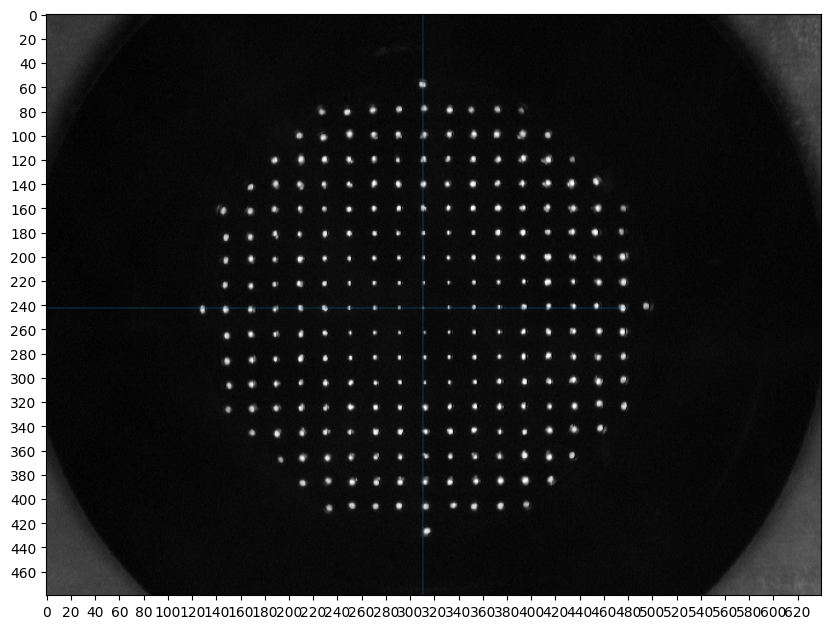

In [179]:
plt.figure(figsize=(10,10))
plt.xticks(np.arange(0,640,20))
plt.yticks(np.arange(0,480,20))
plt.vlines(x=311, ymin=0, ymax=480, lw=0.3)
plt.hlines(y=242, xmin=0, xmax=480, lw = 0.3)
plt.imshow(img_gray, cmap='gray')

In [180]:
h, w = img_gray.shape[:2]
h,w

(480, 640)

In [181]:
#The following code is being built 23/9
centered_img_gray = img_gray[:, 71:552]

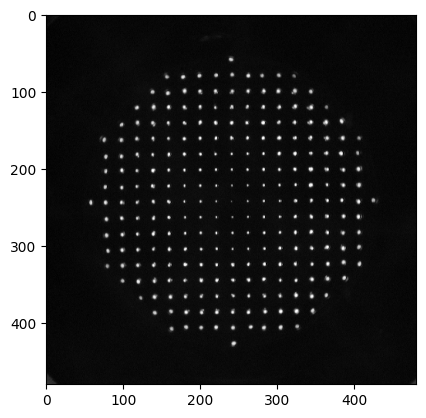

In [182]:
plt.imshow(centered_img_gray, cmap="gray")

In [183]:
out_path = os.path.join(root, "hpref_cropped.tif")
cv.imwrite(out_path, centered_img_gray)
print("Still needs to be fixed, it is not the same")
print("saved to:", out_path)

Still needs to be fixed, it is not the same
saved to: c:\Users\PC\Desktop\UN\OpticsWork\codefiles\thesisreproduction\hpref_cropped.tif


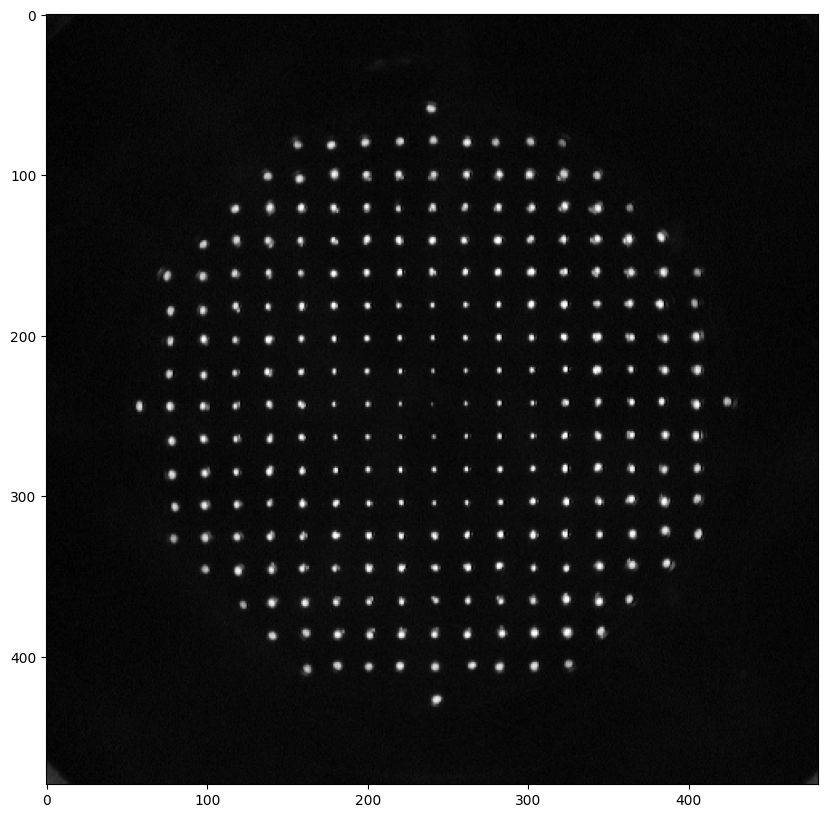

In [184]:
plt.figure(figsize=(10,10))
plt.imshow(centered_img_gray, cmap='gray')

Text(0.5, 1.0, 'Intensities histogram')

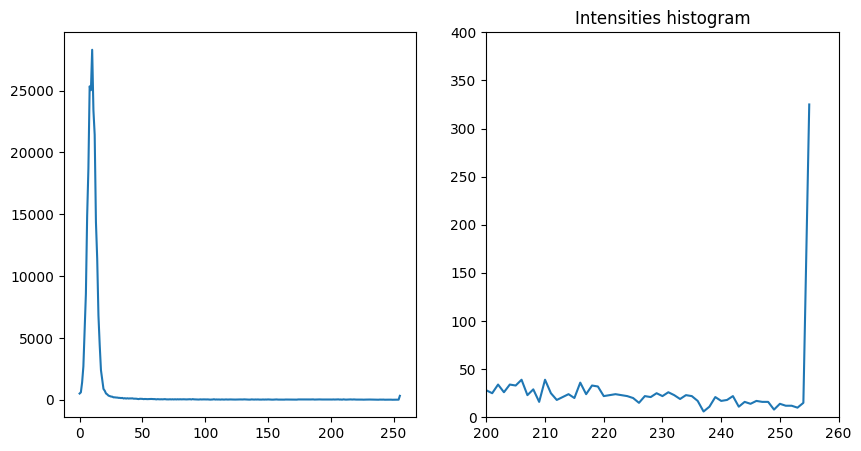

In [185]:
hist = cv.calcHist([centered_img_gray], [0], None, [256], [0,256])
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.plot(hist)


plt.subplot(1,2,2)
plt.plot(hist)
plt.xlim(200,260)
plt.ylim(0,400)

plt.title("Intensities histogram")


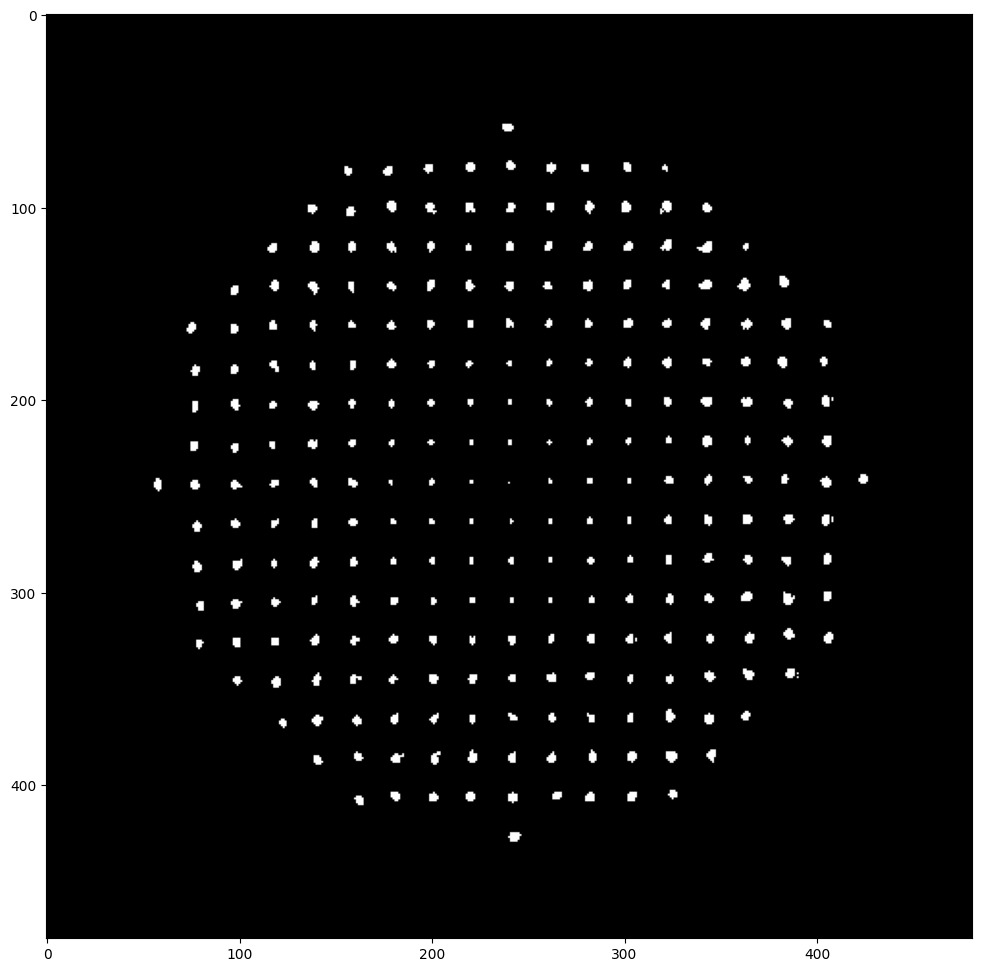

In [186]:
ret,thresh1 = cv.threshold(centered_img_gray,100,255,cv.THRESH_BINARY)
plt.figure(figsize=(12,12))
plt.imshow(thresh1, cmap="gray")

Applying the OTSU algorithm to detect the centroids of the image...

In [187]:
# arb_thres = 255
# max_val = 255

# plt.figure(figsize=(12,12))
# thres, img_otsu = cv.threshold(centered_img_gray, arb_thres, max_val, cv.THRESH_BINARY + cv.THRESH_OTSU)
# plt.imshow(img_otsu, cmap="gray")
# thres

So, we are going to proceed to do the analysis to find the centroids.

In [188]:
#Finding contours in the binarized image:
# contornos, _ = cv.findContours(img_otsu, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
contornos, _ = cv.findContours(thresh1, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

#Array to save the centroids:
centroids_x_coord = []
centroids_y_coord = []


In [189]:
for cnt in contornos:
    area = cv.contourArea(cnt)
    if area > 100:
        #Filtering the contours that are or too large or to small to be assumed as a point with a CM.
        continue
    # Calcular los momentos del contorno para determinar el centroide
    M = cv.moments(cnt)
    if M["m00"] != 0:
        cX = M["m10"] / M["m00"]
        cY = M["m01"] / M["m00"]
        centroids_x_coord.append(cX)
        centroids_y_coord.append(cY)
    else:
        continue

In [190]:
len(centroids_x_coord)

252

Now we proceed to add the central point

In [191]:
centroids_x_coord.append(240)
centroids_y_coord.append(240)

In [192]:
len(centroids_x_coord), len(centroids_y_coord)

(253, 253)

In [194]:
centroids_y_coord

[426.8952380952381,
 407.9166666666667,
 405.92857142857144,
 406.25925925925924,
 405.5,
 406.5,
 406.0,
 406.3472222222222,
 405.79487179487177,
 404.7777777777777,
 387.0833333333333,
 386.1190476190476,
 385.1951219512195,
 385.2043010752688,
 386.051282051282,
 385.89855072463763,
 386.2142857142857,
 385.3174603174603,
 384.4222222222222,
 385.39506172839504,
 385.66666666666663,
 367.78431372549016,
 365.7619047619047,
 366.5466666666666,
 366.4343434343434,
 365.75,
 365.1111111111111,
 365.2857142857143,
 365.1111111111111,
 364.71111111111105,
 365.59649122807014,
 365.8181818181818,
 364.07246376811594,
 364.1764705882353,
 346.5698924731183,
 345.7333333333333,
 345.1666666666667,
 344.87179487179486,
 344.5,
 344.84057971014494,
 344.86419753086415,
 345.0833333333333,
 344.9,
 343.44444444444446,
 344.3066666666666,
 345.3589743589743,
 343.62365591397844,
 342.0123456790123,
 342.55555555555554,
 326.66666666666663,
 325.5,
 325.92753623188406,
 324.7333333333333,
 325.0

In [199]:
matA = np.zeros((480,480))
matX_coord = np.zeros((480, 480))
matY_coord = np.zeros((480, 480))

In [203]:
for i in range(253):
    matA[int(centroids_x_coord[i])][int(centroids_y_coord[i])] = 1
    matX_coord[int(centroids_y_coord[i])][int(centroids_x_coord[i])] = (centroids_x_coord[i])
    matY_coord[int(centroids_y_coord[i])][int(centroids_x_coord[i])] = (centroids_y_coord[i])

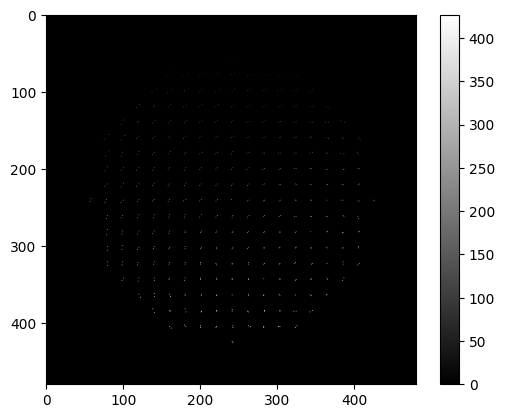

In [205]:
plt.imshow( matY_coord, cmap="gray")
plt.colorbar()

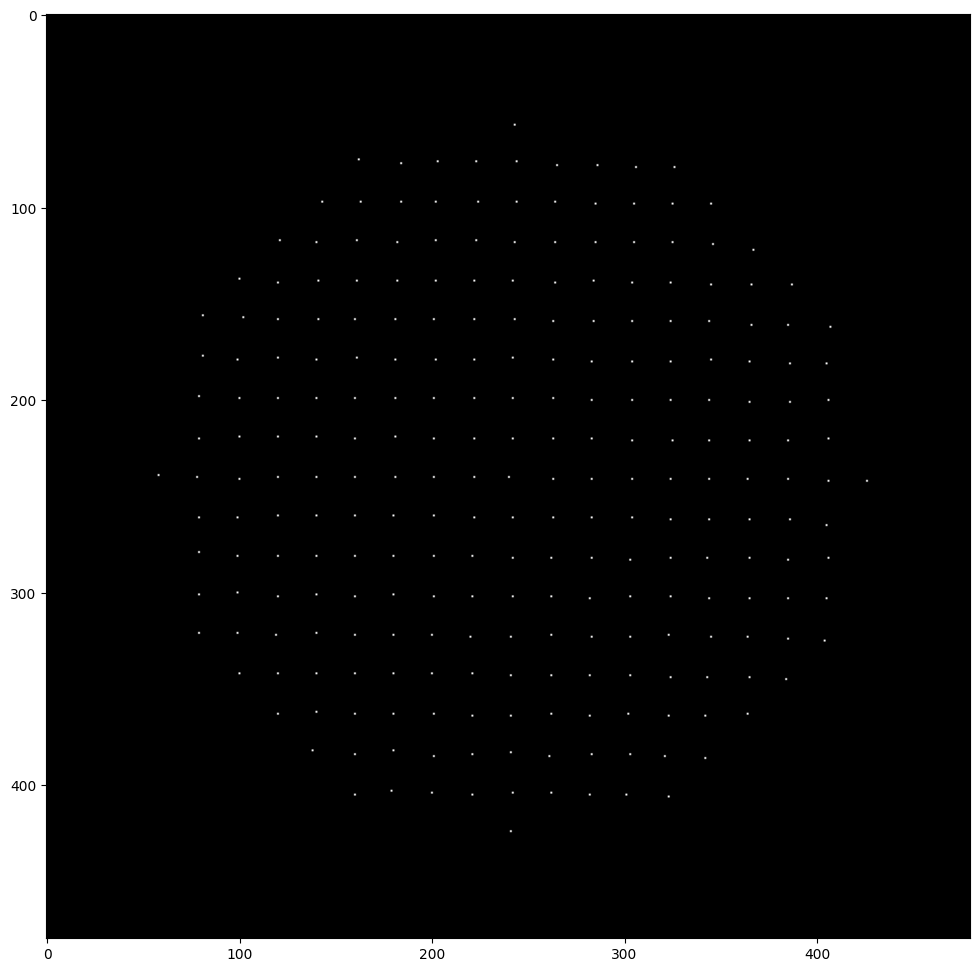

In [206]:
plt.figure(figsize=(12,12))
plt.imshow(matA, cmap="gray")
# plt.xticks(np.arange(0, 480, 30))
# plt.yticks(np.arange(0, 480, 30))

In [207]:
counter = 1
with open("21-10-output.txt", "w") as f:
    for a, b in zip(centroids_x_coord, centroids_y_coord):   # iterate over both arrays at once
        f.write(f"{counter} {b:.6f} {a:.6f}\n")
        counter += 1

<h2><center> <b> Mask Generator</b> <center>

Now, we are going to proceed to generate a mask of radius three in order to label correctly each one of the points to perform the numerical derivative.

In [209]:
def mask_generator(img_mat, radius):
    centroids = []
    centroids_region = []
    N = 480
    matA_mask = np.zeros_like(img_mat)
    for ii in range(N): #This will help us to iterate across the x-axis (columns)
        for jj in range(N): ##This will help us to iterate across the y-axis (rows)
            if matA[ii][jj] != 0: #Interval to iterate and generate the mask
                centroids.append([matX_coord[ii][jj],matY_coord[ii][jj]])
                regional_coords = []
                for kk in range(ii-radius, ii + radius + 1):
                    for ll in range(jj-radius, jj + radius + 1):
                        d = np.sqrt((kk-ii)**2+(ll-jj)**2)
                        regional_coords.append([matX_coord[ii][jj],matY_coord[ii][jj]])
                        if (d <= radius):
                            matA_mask[kk][ll] = 1   
                            regional_coords.append([kk,ll])
                regional_coords.append({'region':0})
                centroids_region.append(regional_coords)
    return matA_mask, centroids, centroids_region

In [210]:
mask_r, centroids, centroids_region = mask_generator(matA, 7)

In [211]:
len(centroids)
centroids

[[243.9012345679012, 57.654320987654316],
 [162.53571428571428, 75.10714285714286],
 [203.38596491228068, 76.96491228070175],
 [223.92753623188403, 76.44927536231884],
 [244.07692307692307, 76.88461538461539],
 [184.66666666666663, 77.18666666666667],
 [265.66666666666663, 78.0],
 [286.67816091954023, 78.08045977011493],
 [306.9, 79.71666666666667],
 [326.66666666666663, 79.16666666666666],
 [143.0, 97.5],
 [163.0, 97.39393939393939],
 [184.07936507936506, 97.44444444444444],
 [202.34567901234567, 97.80246913580247],
 [224.80701754385964, 97.66666666666666],
 [244.05555555555554, 97.8611111111111],
 [264.28985507246375, 97.92753623188405],
 [285.66666666666663, 98.92857142857143],
 [305.9012345679012, 98.19753086419752],
 [325.92753623188406, 98.55072463768116],
 [345.7333333333333, 98.85],
 [121.07692307692308, 117.20512820512819],
 [161.26666666666665, 117.4],
 [202.57777777777775, 117.42222222222222],
 [223.39393939393938, 117.06060606060605],
 [140.53571428571428, 118.3690476190476

In [212]:
v_initial_cols = np.min(centroids_y_coord)
v_final_cols   = np.max(centroids_y_coord)

v_initial_rows = np.min(centroids_x_coord)
v_final_rows   = np.max(centroids_x_coord)

In [213]:
len(centroids_region[0])

375

In [223]:
centroids_region[2][-1]

{'region': 0}

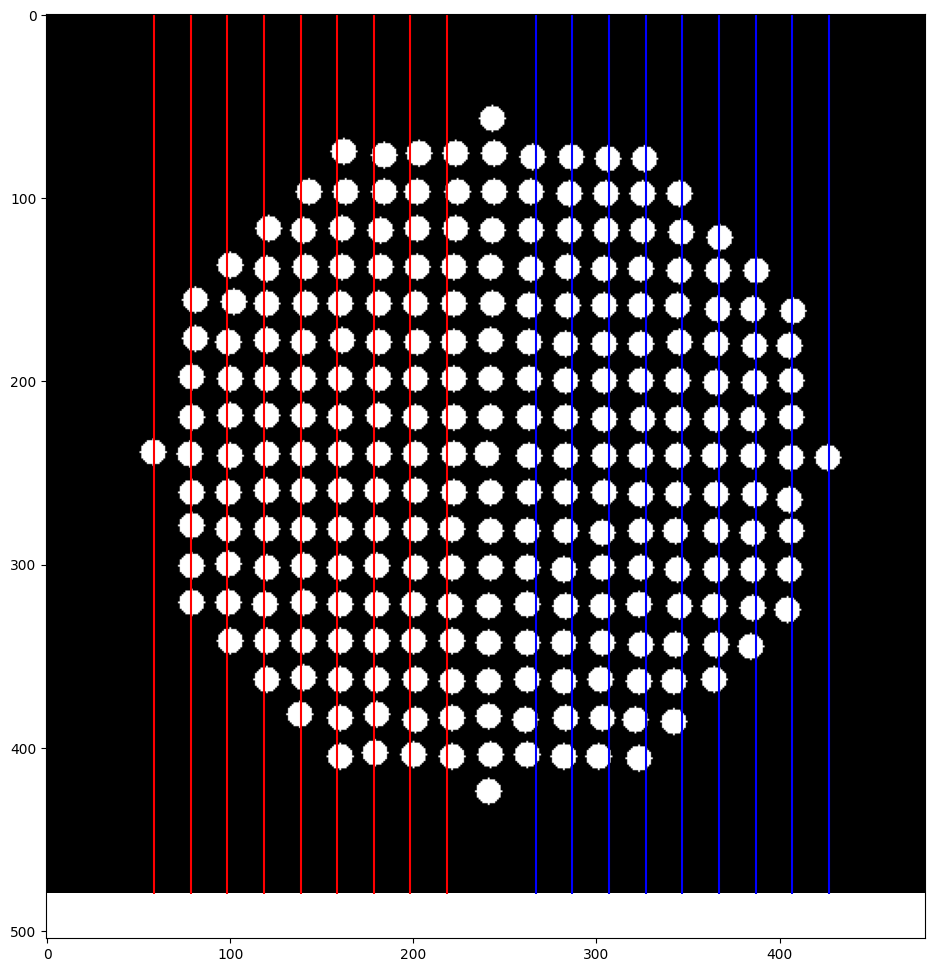

In [215]:
plt.figure(figsize=(12,12))
plt.imshow(mask_r, cmap="gray")

vals_to_iterate = []

for i in range(0,9):
    plt.vlines(x=v_initial_cols+20*i, ymin= 0, ymax=480, color='r')
    vals_to_iterate.append(int(v_initial_cols+20*i))


for j in range(0, 9):
    plt.vlines(x=v_final_cols-20*j, ymin= 0, ymax=480, color='b')
    vals_to_iterate.append(int(v_final_cols-20*j))

vals_to_iterate.append(242)

In [216]:
vals_to_iterate = np.sort(vals_to_iterate)

In [217]:
vals_to_iterate

array([ 58,  78,  98, 118, 138, 158, 178, 198, 218, 242, 266, 286, 306,
       326, 346, 366, 386, 406, 426])

In [218]:
label = 1
for ii in vals_to_iterate:
    jj = 0
    while(jj < 480):
        if mask_r[ii][jj] != 0:
            kk = jj + 1
            while(mask_r[ii][kk] != 0):
                kk += 1
            jj = kk - 1
            for mm in centroids_region:
                if ([matX_coord[ii,jj], matY_coord[ii][jj]] in mm):
                    print("I have found something")
                    mm[-1] = {'region': label}
                    break
            label += 1
        jj += 1

In [219]:
for cc in centroids:
    for rr in centroids_region:
        if cc in rr:
            cc.append(rr[-1]['region'])
            break

In [220]:
centroids

[[243.9012345679012, 57.654320987654316, 0],
 [162.53571428571428, 75.10714285714286, 0],
 [203.38596491228068, 76.96491228070175, 0],
 [223.92753623188403, 76.44927536231884, 0],
 [244.07692307692307, 76.88461538461539, 0],
 [184.66666666666663, 77.18666666666667, 0],
 [265.66666666666663, 78.0, 0],
 [286.67816091954023, 78.08045977011493, 0],
 [306.9, 79.71666666666667, 0],
 [326.66666666666663, 79.16666666666666, 0],
 [143.0, 97.5, 0],
 [163.0, 97.39393939393939, 0],
 [184.07936507936506, 97.44444444444444, 0],
 [202.34567901234567, 97.80246913580247, 0],
 [224.80701754385964, 97.66666666666666, 0],
 [244.05555555555554, 97.8611111111111, 0],
 [264.28985507246375, 97.92753623188405, 0],
 [285.66666666666663, 98.92857142857143, 0],
 [305.9012345679012, 98.19753086419752, 0],
 [325.92753623188406, 98.55072463768116, 0],
 [345.7333333333333, 98.85, 0],
 [121.07692307692308, 117.20512820512819, 0],
 [161.26666666666665, 117.4, 0],
 [202.57777777777775, 117.42222222222222, 0],
 [223.3939

In [221]:
label = 1
for ii in vals_to_iterate:
    init = 0.0
    for jj in range(0,480, 1):
        if mask_r[ii][jj] != 0:
            for kk in centroids_region:
                if (ii,jj,0) in kk:
                    for ll in range(len(kk)):
                        kk[ll][2] = label

In [222]:
file_name = "output_organized.txt"
with open(file_name, 'w') as file:
    for item in centroids:
        file.write(str(item[2]) + " " + str(item[0])+ " "+ str(item[1])+ "\n")

In [225]:
import cv2 as cv
import numpy as np
import os

# -------------------------------------------------------------------
# ### TUNE THIS VALUE ###
# Start with 50. If you get < 253 blobs, try 40. If you get too many, try 60.
threshold_value = 60
# -------------------------------------------------------------------

# --- Load Image ---
root = os.getcwd()
img_path = os.path.join(root, "hpref_cropped.tif") 
img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

if img_gray is None:
    print(f"Error: Could not load image 'hpref_cropped.tif'.")
else:
    print(f"Successfully loaded image 'hpref_cropped.tif' with shape {img_gray.shape}")
    
    # --- Get Binary Mask ---
    ret, binary_mask = cv.threshold(img_gray, threshold_value, 255, cv.THRESH_BINARY)
    
    # --- Get Stats for ALL Blobs ---
    num_labels, labels_matrix, stats, centroids = cv.connectedComponentsWithStats(binary_mask)
    
    all_blob_sizes = stats[1:, cv.CC_STAT_AREA]
    all_blob_sizes_sorted = sorted(all_blob_sizes, reverse=True)
    
    print(f"Found {len(all_blob_sizes_sorted)} total blobs with threshold={threshold_value}.")
    
    if len(all_blob_sizes_sorted) < 253:
        print("\n*** ACTION NEEDED: You found less than 253 spots. ***")
        print("*** Try lowering the 'threshold_value' (e.g., to 40) and run again. ***")
    else:
        # Print all sizes, with a marker at #253
        for i, size in enumerate(all_blob_sizes_sorted):
            print(f"Blob #{i+1}: {size} pixels")
            if i == 252: # This is the 253rd blob
                print("---------------------------------")
                print("--- THIS IS YOUR 253rd SPOT ---")
                print(f"--- ITS SIZE IS {size} PIXELS ---")
                print("---------------------------------")

        size_of_253rd_spot = all_blob_sizes_sorted[252] 
        size_of_254th_blob = all_blob_sizes_sorted[253]
        
        suggested_min_size = (size_of_253rd_spot + size_of_254th_blob) / 2
        
        print(f"\n*** SUCCESS! You found all 253 spots. ***")
        print(f"The 253rd spot has size {size_of_253rd_spot}.")
        print(f"The 254th (noise) blob has size {size_of_254th_blob}.")
        print(f"*** Use this value for min_spot_size in your main script: {int(suggested_min_size)} ***")

Successfully loaded image 'hpref_cropped.tif' with shape (480, 480)
Found 268 total blobs with threshold=60.
Blob #1: 48 pixels
Blob #2: 43 pixels
Blob #3: 42 pixels
Blob #4: 41 pixels
Blob #5: 40 pixels
Blob #6: 40 pixels
Blob #7: 38 pixels
Blob #8: 38 pixels
Blob #9: 35 pixels
Blob #10: 35 pixels
Blob #11: 35 pixels
Blob #12: 35 pixels
Blob #13: 35 pixels
Blob #14: 35 pixels
Blob #15: 35 pixels
Blob #16: 35 pixels
Blob #17: 34 pixels
Blob #18: 34 pixels
Blob #19: 34 pixels
Blob #20: 34 pixels
Blob #21: 34 pixels
Blob #22: 34 pixels
Blob #23: 34 pixels
Blob #24: 34 pixels
Blob #25: 34 pixels
Blob #26: 33 pixels
Blob #27: 33 pixels
Blob #28: 33 pixels
Blob #29: 33 pixels
Blob #30: 33 pixels
Blob #31: 33 pixels
Blob #32: 32 pixels
Blob #33: 32 pixels
Blob #34: 32 pixels
Blob #35: 32 pixels
Blob #36: 32 pixels
Blob #37: 32 pixels
Blob #38: 31 pixels
Blob #39: 31 pixels
Blob #40: 31 pixels
Blob #41: 31 pixels
Blob #42: 31 pixels
Blob #43: 30 pixels
Blob #44: 30 pixels
Blob #45: 30 pixels


Successfully loaded image 'hpref_cropped.tif' with shape (480, 480)
Created binary mask with threshold=70.
[196  77   6   6  26]
Found 264 total blobs (including noise).

Smallest real spot (Blob #253) has 3 pixels.
Largest noise blob (Blob #254) has 2 pixels.
--- Automatically setting min_spot_size to: 2 ---
Kept 253 spots after filtering.
Calculated 253 precise sub-pixel centroids.
Added the center point (240.0, 240.0). Total points to sort: 254
Sorted all centroids correctly using column clustering.
Successfully saved 254 precise, sorted centroids to 13-10-centros_Yobod.txt


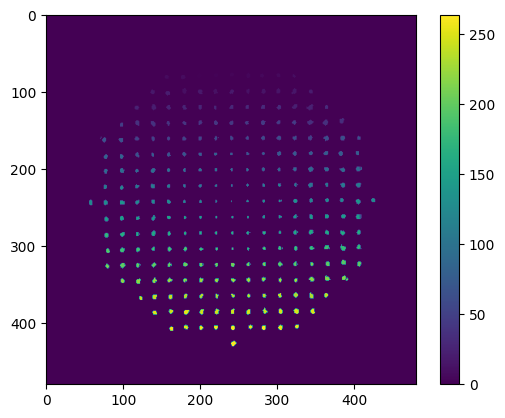

In [ ]:
import cv2 as cv
import numpy as np
import scipy.ndimage as ndi
import os
from sklearn.cluster import KMeans

# -------------------------------------------------------------------
# ### 1. SET YOUR PARAMETERS HERE ###
#
# You only need to tune this one value.
# Start with 60. If you get < 253 blobs, try 50. If still too few, try 40.
threshold_value = 70
#
# (The files you are using)
image_filename = "hpref_cropped.tif"
output_filename = "13-10-centros_Yobod.txt"
#
# (The number of columns and spots you expect)
number_of_columns = 19
expected_spots = 253
# -------------------------------------------------------------------

# --- 2. Load the Image ---
root = os.getcwd()
img_path = os.path.join(root, image_filename)
img_gray = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

if img_gray is None:
    print(f"Error: Could not load image '{image_filename}'.")
    print("Make sure it is in the same directory as the script.")
else:
    print(f"Successfully loaded image '{image_filename}' with shape {img_gray.shape}")

    # --- 3. Isolate the Spots (Get Binary Mask) ---
    ret, binary_mask = cv.threshold(img_gray, threshold_value, 255, cv.THRESH_BINARY)
    print(f"Created binary mask with threshold={threshold_value}.")

    # --- 4. Find and Label All Spots (with Stats) ---
    num_labels, labels_matrix, stats, centroids = cv.connectedComponentsWithStats(binary_mask)
    
    plt.imshow(labels_matrix)
    plt.colorbar()

    print(stats[2, :])

    # Get the size (area) of all blobs, skipping the background (label 0)
    all_blob_sizes = stats[1:, cv.CC_STAT_AREA]
    # Here, it orders from the biggest to the smallest one
    all_blob_sizes_sorted = sorted(all_blob_sizes, reverse=True)
    
    print(f"Found {len(all_blob_sizes_sorted)} total blobs (including noise).")

    # --- 5. AUTOMATICALLY Find the 'min_spot_size' ---
    # (This is the "diagnostic" code, now integrated)
    
    if len(all_blob_sizes_sorted) < expected_spots:
        print("\n*** ERROR: Found fewer than {expected_spots} spots. ***")
        print("*** Try lowering the 'threshold_value' (e.g., to 50 or 40) and run again. ***")
    else:
        # This is the size of your smallest "real" spot
        size_of_last_spot = all_blob_sizes_sorted[expected_spots - 1] # Index 252 is the 253rd item
        
        # This is the size of the largest "noise" blob
        size_of_first_noise = all_blob_sizes_sorted[expected_spots]   # Index 253 is the 254th item
        
        # We automatically set the minimum size to be halfway between them
        min_spot_size = (size_of_last_spot + size_of_first_noise) / 2
        
        print(f"\nSmallest real spot (Blob #{expected_spots}) has {size_of_last_spot} pixels.")
        print(f"Largest noise blob (Blob #{expected_spots + 1}) has {size_of_first_noise} pixels.")
        print(f"--- Automatically setting min_spot_size to: {int(min_spot_size)} ---")

        # --- 6. Filter out Noise ---
        valid_indices = []
        for label_id in range(1, num_labels): # Loop from 1 (skip background 0)
            if stats[label_id, cv.CC_STAT_AREA] > min_spot_size:
                valid_indices.append(label_id)
                
        print(f"Kept {len(valid_indices)} spots after filtering.")

        # --- 7. Calculate Precise Intensity-Weighted Centroids ---
        precise_centroids_yx = ndi.center_of_mass(img_gray, labels=labels_matrix, index=valid_indices)
        print(f"Calculated {len(precise_centroids_yx)} precise sub-pixel centroids.")

        # --- 8. Organize Centroids with Clustering ---
        centroids_xy = [(coord[1], coord[0]) for coord in precise_centroids_yx]
        
        # Add the (240, 240) center point to the list
        center_point = (240.0, 240.0)
        centroids_xy.append(center_point)
        print(f"Added the center point {center_point}. Total points to sort: {len(centroids_xy)}")

        # Prepare data for clustering
        x_coords = np.array([c[0] for c in centroids_xy]).reshape(-1, 1)

        # Check if we have enough points to cluster
        if len(x_coords) < number_of_columns:
            print(f"\n*** ERROR: Not enough spots ({len(x_coords)}) to create {number_of_columns} columns. ***")
            print("*** Your 'min_spot_size' might be too high or 'threshold_value' is wrong. ***")
        else:
            # Initialize and run KMeans to group spots into columns
            kmeans = KMeans(n_clusters=number_of_columns, n_init=10, random_state=0)
            column_labels = kmeans.fit_predict(x_coords)
            
            # Get the X-coordinate of each cluster center
            cluster_centers = kmeans.cluster_centers_.flatten()
            
            # Get the sorted order of the clusters
            cluster_sort_order = np.argsort(cluster_centers)
            
            # Create a map: {original_cluster_id: sorted_column_label}
            cluster_map = {original_id: sorted_id for sorted_id, original_id in enumerate(cluster_sort_order)}

            # Create a new list we can sort properly
            sortable_list = []
            for i in range(len(centroids_xy)):
                spot_xy = centroids_xy[i]
                original_cluster_id = column_labels[i]
                sorted_column_label = cluster_map[original_cluster_id]
                y_coord = spot_xy[1]
                sort_key = (sorted_column_label, y_coord)
                sortable_list.append( (sort_key, spot_xy) )

            # Sort the list based on the key (column, then y)
            sorted_list_of_tuples = sorted(sortable_list, key=lambda item: item[0])
            
            # Extract just the (x, y) coordinates, now in the perfect order
            sorted_centroids = [item[1] for item in sorted_list_of_tuples]

            print("Sorted all centroids correctly using column clustering.")

            # --- 9. Save to File ---
            with open(output_filename, 'w') as f:
                for i, (x_coord, y_coord) in enumerate(sorted_centroids):
                    label = i + 1
                    # Save in the format: label X_float Y_float
                    f.write(f"{label} {x_coord:.8f} {y_coord:.8f}\n")

            print(f"Successfully saved {len(sorted_centroids)} precise, sorted centroids to {output_filename}")